In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from filterpy.kalman import KalmanFilter
import filterpy
from matplotlib.tri import Triangulation
from matplotlib.patches import Ellipse
import pandas as pd

rc({"text.usetex": True
    ,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 14})

# test premo enakomerno

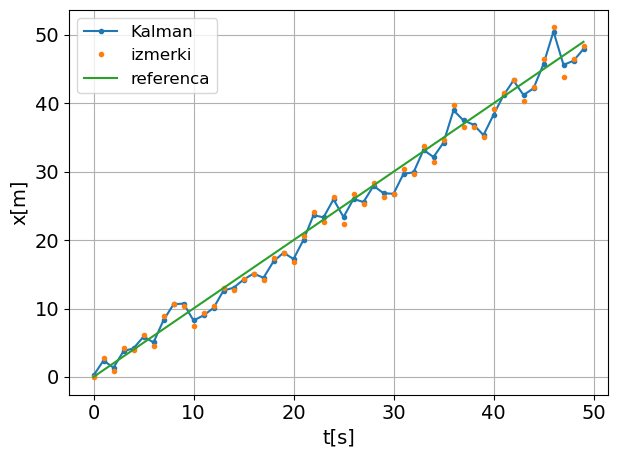

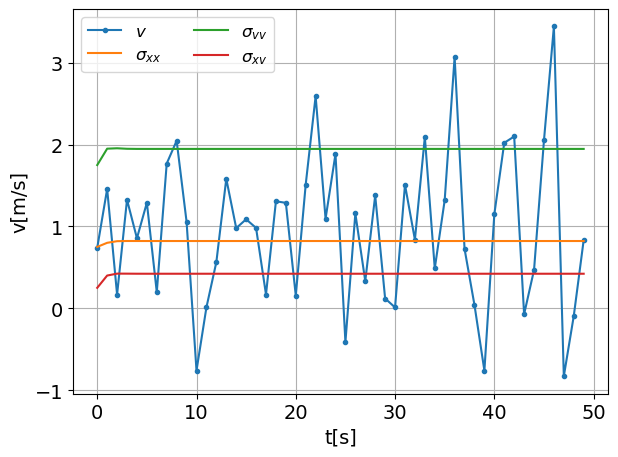

In [2]:
dt=1
std=2
x_ref=np.arange(0,50,1) #hitrost = 1 m/s
x= x_ref+ 1*np.random.normal(0,std,size=50)

F_n=np.array([[1,dt],[0,1]]) #state transition
P_0=np.array([[1,0],[0,1]]) #covariance initial

f=KalmanFilter(dim_x=2,dim_z=1,dim_u=0)
f.F=F_n
f.P=P_0
f.x=np.array([[0],[1]])
f.H=np.array([[1,0]])

pos=[]
hitr=[]
covariance=[]
for i in range(len(x)):
    f.predict()
    f.update(x[i])
    pos.append(f.x[0,0])
    hitr.append(f.x[1,0])
    covariance.append(f.P)
covariance = np.array(covariance)
plt.plot(pos,'.-',label='Kalman')
plt.plot(x,'.',label='izmerki')
plt.plot(x_ref,'-',label='referenca')
plt.legend(fontsize=12)
plt.grid()
plt.xlabel('t[s]')
plt.ylabel('x[m]')
plt.tight_layout()
#plt.savefig('slike/test_1d_x.pdf')
plt.show()

plt.plot(hitr,'.-',label='$v$')
plt.plot(covariance[:,0,0],label='$\sigma_{xx}$')
plt.plot(covariance[:,1,1],label='$\sigma_{vv}$')
plt.plot(covariance[:,0,1],label='$\sigma_{xv}$')
plt.legend(loc='best', ncol=2, fontsize=12)
plt.grid()
plt.xlabel('t[s]')
plt.ylabel('v[m/s]')
plt.tight_layout()
#plt.savefig('slike/test_1d_v.pdf')

# NALOGA

In [3]:
t,px,py,pvx,pvy,pax,pay = np.loadtxt('podatki/kalman_cartesian_data.dat',unpack=True)
kt,kx,ky,kvx,kvy = np.loadtxt('podatki/kalman_cartesian_kontrola.dat',unpack=True)

(-199.04202848294233, 437.71578184150184)

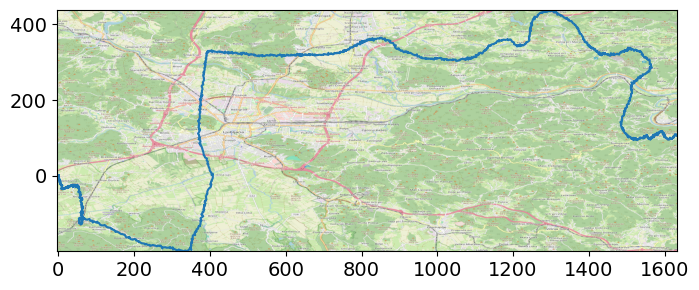

In [4]:
h = (px / (6000 / 360))
v = ((py / (3000 / 180)))

BBox = (h.min()-0.1,   h.max()+0.1,
        v.min()-0.1, v.max()+0.1)
map_img=plt.imread('podatki/map.png')

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(map_img, zorder=0, extent=BBox, aspect='equal')
ax.plot(h,v, '-')
ax.set_xlim(BBox[0], BBox[1])
ax.set_ylim(BBox[2], BBox[3])

In [14]:
def Kalman2D(step_pos,step_v,cov=False,x_0=None,brez_kontrole=False):
    # PODATKI
    dt=1.783 #s
    sigma_xy_data = 25 #m abs. napaka
    sigma_a = 0.05 #m/s**2
    sigma_v=0.01*np.abs(np.sqrt(pvx**2+pvy**2)) #ni konst. relat.napaka
    sigma_v=np.array([1/3.6 if i>1/3.6 else i for i in sigma_v]) #omejimo na 1 km/h=1/3,6=0,2777 m/s

    if brez_kontrole:
        print('brez kontrolnega vektorja')
        f=KalmanFilter(dim_x=4,dim_z=4,dim_u=0) #u=kontrola, x-kaj spremljamo, z-kaj je izmerjeno
    else:
        f=KalmanFilter(dim_x=4,dim_z=4,dim_u=2) #uporabimo kontrolni vektor
        f.Q=np.diag([0,0,sigma_a**2*dt**2,sigma_a**2*dt**2],)#napaka pospeškov - process noise
        #f.Q = filterpy.common.Q_discrete_white_noise(dim=4, dt=0.1, var=0.13)
    f.B = np.block([[0.5*np.identity(2)*dt**2],
                    [np.identity(2)*dt]]) #control transition matrix
    f.x=np.transpose([[px[0],py[0],pvx[0],pvy[0]]]) #initial
    if x_0 != None:
        f.x=np.reshape(x_0,np.shape(f.x))
        #print('podan začetni približek:',f.x)
    
    sigma_xx=sigma_yy=sigma_xy_data
    sigma_vxvx=sigma_vyvy=sigma_vxvy=sigma_v[0]
    sigma_xy=sigma_xvx=sigma_xvy=sigma_yvx=sigma_yvy=0 #ok???
    f.P = np.array([[sigma_xx, sigma_xy, sigma_xvx, sigma_xvy],
                    [sigma_xy, sigma_yy, sigma_yvx, sigma_yvy],
                    [sigma_xvx, sigma_yvx, sigma_vxvx, sigma_vxvy],
                    [sigma_xvy, sigma_yvy, sigma_vxvy, sigma_vyvy]]) #covariance matrix initial

    R_v=np.diag([sigma_xy_data**2,sigma_xy_data**2,sigma_v[0]**2,sigma_v[0]**2])#napaka hitrosti in pomikov, šum
    f.R = R_v # measurment noise - initial

    f.H = np.identity(4) #measurment matrix - kaj merimo, kaj računamo izmerek z=H*x
    f.F=np.block([[np.identity(2), np.identity(2)*dt],
                [np.zeros((2,2)), np.identity(2)]]) #state transition matrix

    saver = filterpy.common.Saver(f)
    for i in range(0,len(px)):
        if brez_kontrole:
            f.predict()
        else:
            c=np.transpose([[pax[i]*dt,pay[i]*dt]])
            f.predict(u=c)
        z=np.transpose([[px[i],py[i],pvx[i],pvy[i]]])
        R_i=np.diag([sigma_xy_data**2,sigma_xy_data**2,sigma_v[i]**2,sigma_v[i]**2])
        if step_pos==step_v and i%step_pos==0:
            #z=np.transpose([[px[i],py[i],0,0]])
            H_i=np.block([[np.identity(2), np.zeros((2,2))],
                        [np.zeros((2,2)), np.identity((2))]])
            f.update(z,R=R_i,H=H_i)
        elif i%step_pos==0:
            #z=np.transpose([[px[i],py[i],0,0]])
            H_i=np.block([[np.identity(2), np.zeros((2,2))],
                        [np.zeros((2,2)), np.zeros((2,2))]])
            f.update(z,R=R_i,H=H_i)
        elif i%step_v==0:
            #z=np.transpose([[0,0,pvx[i],pvy[i]]])
            H_i=np.block([[np.zeros((2,2)), np.zeros((2,2))],
                        [np.zeros((2,2)), np.identity(2)]])
            f.update(z,R=R_i,H=H_i)
        else:
            H_i=np.zeros_like(f.H)
            f.update(z,R=R_i,H=H_i)
        saver.save()
    saver.to_array()
    if cov:
        kovariance = saver.P #to so matrike
        return kovariance
    else:
        res_x= np.transpose(saver.x[:,0])[0]
        res_y= np.transpose(saver.x[:,1])[0]
        res_vx= np.transpose(saver.x[:,2])[0]
        res_vy= np.transpose(saver.x[:,3])[0]
        return res_x, res_y, res_vx, res_vy
def Kalman_old(step_pos,step_v,cov=False):#ni več v uporabi!
    # PODATKI
    dt=1.783 #s
    sigma_xy = 25 #m abs. napaka
    sigma_a = 0.05 #m/s**2
    sigma_v=0.01*np.abs(np.sqrt(pvx**2+pvy**2)) #ni konst. relat.napaka
    sigma_v=np.array([1/3.6 if i>1/3.6 else i for i in sigma_v]) #omejimo na 1 km/h=1/3,6=0,2777 m/s

    #f=KalmanFilter(dim_x=4,dim_z=4,dim_u=0) #u=kontrola, x-kaj spremljamo, z-kaj je izmerjeno - u=0 ni kontrole s pospeški
    f=KalmanFilter(dim_x=4,dim_z=4,dim_u=2) #uporabimo kontrolni vektor
    f.B = np.block([[0.5*np.identity(2)*dt**2],
                   [np.identity(2)*dt]]) #control transition matrix

    f.x=np.transpose([[px[0],py[0],pvx[0],pvy[0]]]) #initial
    sigma_xx=sigma_yy=sigma_xy
    sigma_vxvx=sigma_vyvy=sigma_vxvy=sigma_v[0]
    sigma_xvx=sigma_xvy=sigma_yvx=sigma_yvy=0 #ok???
    f.P = np.array([[sigma_xx, sigma_xy, sigma_xvx, sigma_xvy],
                    [sigma_xy, sigma_yy, sigma_yvx, sigma_yvy],
                    [sigma_xvx, sigma_yvx, sigma_vxvx, sigma_vxvy],
                    [sigma_xvy, sigma_yvy, sigma_vxvy, sigma_vyvy]]) #covariance matrix

    Q_a=np.diag([0,0,sigma_a**2*dt**2,sigma_a**2*dt**2],)#napaka pospeškov
    f.Q=Q_a #process noise
    #f.Q = filterpy.common.Q_discrete_white_noise(dim=4, dt=0.1, var=0.13)
    R_v=np.diag([sigma_xy**2,sigma_xy**2,sigma_v[0]**2,sigma_v[0]**2])#napaka hitrosti in pomikov, šum
    f.R = R_v # measurment noise

    f.H = np.identity(4) #measurment matrix - kaj merimo, kaj računamo! izmerek z=H*x
    f.F=np.block([[np.identity(2), np.identity(2)*dt],
                [np.zeros((2,2)), np.identity(2)]]) #state transition matrix

    saver = filterpy.common.Saver(f)
    for i in range(len(px)):
        c=np.transpose([[pax[i]*dt,pay[i]*dt]])
        f.predict(u=c)
        #f.predict()
        z=np.transpose([[px[i],py[i],pvx[i],pvy[i]]])
        R_i=np.diag([sigma_xy**2,sigma_xy**2,sigma_v[i]**2,sigma_v[i]**2])
        if i%step_pos==0:
            H_i=np.block([[np.identity(2), np.zeros((2,2))],
                        [np.zeros((2,2)), np.zeros((2,2))]])
            f.update(z,R=R_i,H=H_i)
        if i%step_v==0:
            H_i=np.block([[np.zeros((2,2)), np.zeros((2,2))],
                        [np.zeros((2,2)), np.identity(2)]])
            f.update(z,R=R_i,H=H_i)
        saver.save()
    saver.to_array()
    if cov:
        kovariance = saver.P #to so matrike
        return kovariance
    else:
        res_x= np.transpose(saver.x[:,0])[0]
        res_y= np.transpose(saver.x[:,1])[0]
        res_vx= np.transpose(saver.x[:,2])[0]
        res_vy= np.transpose(saver.x[:,3])[0]
        return res_x, res_y, res_vx, res_vy

brez kontrolnega vektorja


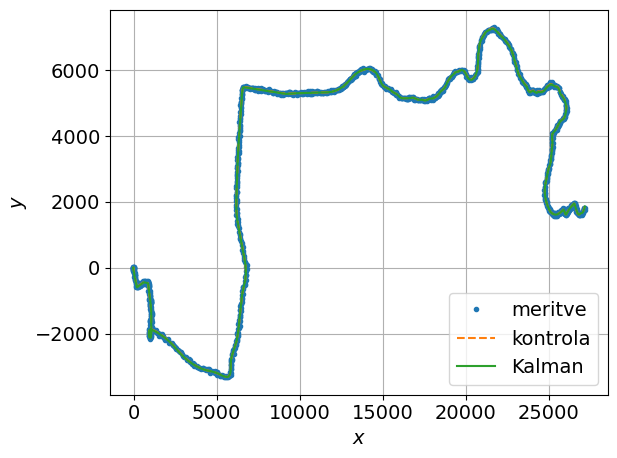

In [6]:
step_pos=1
step_v=step_pos
rx,ry,rvx,rvy = Kalman2D(step_pos,step_v)
#rxb,ryb,rvxb,rvyb= Kalman_old(step_pos,step_v)
rxb,ryb,rvxb,rvyb = Kalman2D(step_pos,step_v,brez_kontrole=True)

start, stop = (0,2500)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman')
#plt.plot(rxb[start:stop],ryb[start:stop],'-',label='brez $\mathbf{u}$')
plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_vse.pdf')

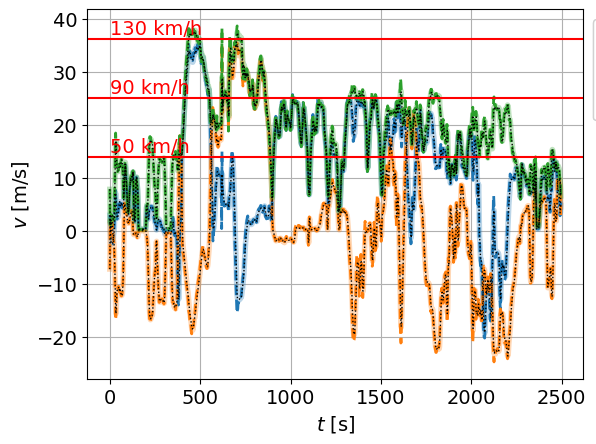

In [7]:
plt.plot(t,pvx,'C0-',label='$v_x$',alpha=0.3,linewidth=4)
plt.plot(t,pvy,'C1-',label='$v_y$',alpha=0.3,linewidth=4)
plt.plot(t,rvx,'C0--',linewidth=2)
plt.plot(t,rvy,'C1--',linewidth=2)
plt.plot(t,np.sqrt(pvx**2+pvy**2),'C2-',label='$\\vec{v}$',alpha=0.3,linewidth=4)
plt.plot(t,np.sqrt(rvx**2+rvy**2),'C2--',linewidth=2)
plt.plot(t,np.sqrt(kvx**2+kvy**2),'k:',linewidth=1)
plt.plot(t,kvx,'k:',linewidth=1)
plt.plot(t,kvy,'k:',linewidth=1)
plt.axhline(130/3.6, color='r')
plt.axhline(90/3.6, color='r')
plt.axhline(50/3.6, color='r')
plt.text(0, 130/3.6+1, '130 km/h', color='r')
plt.text(0, 90/3.6+1, '90 km/h', color='r')
plt.text(0, 50/3.6+1, '50 km/h', color='r')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-',alpha=0.3,linewidth=4, label='izmerki'),
                                         plt.Line2D([], [], color='k', linestyle='--',linewidth=2, label='Kalman'),
                                        plt.Line2D([], [], color='k', linestyle=':', label='kontrola')],
                                loc='upper left', bbox_to_anchor=(-0,1.15), ncol=3)
a1=plt.gca().add_artist(legend_line_styles)
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='C0', label='$v_x$'),
                                         plt.Line2D([], [], color='C1', label='$v_y$'),
                                         plt.Line2D([], [], color='C2', label='$|\\mathbf{v}|$')],
                                loc='best', bbox_to_anchor=(1,1), ncol=1)
a2=plt.gca().add_artist(legend_line_styles)
plt.grid()
plt.xlabel("$t$ [s]")
plt.ylabel("$v$ [m/s]")
#plt.tight_layout()
#plt.savefig('slike/potek_hitrosti.pdf',bbox_inches='tight',bbox_extra_artists=(a1,a2))
plt.show()

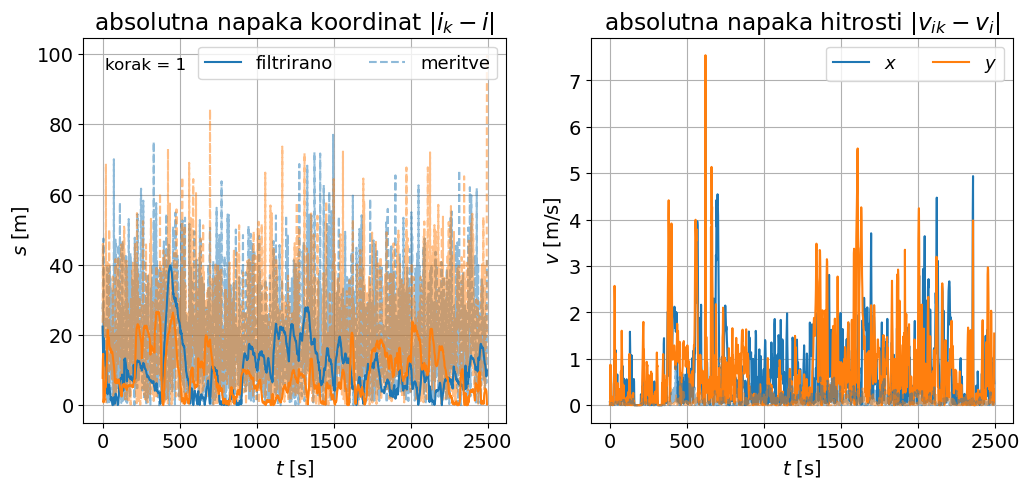

In [8]:
#rez
napaka_x = abs(kx-rx)
napaka_y = abs(ky-ry)
napaka_vx = abs(kvx-rvx)
napaka_vy = abs(kvy-rvy)
#meritve
napaka_xm = abs(kx-px)
napaka_ym = abs(ky-py)
napaka_vxm = abs(kvx-pvx)
napaka_vym = abs(kvy-pvy)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(t,napaka_xm,'C0--', alpha=0.5)
ax1.plot(t,napaka_ym,'C1--', alpha=0.5)

ax1.plot(t,napaka_x,'C0',label='$x$')
ax1.plot(t,napaka_y,'C1',label='$y$')
ax2.plot(t,napaka_vx,'C0',label='$x$')
ax2.plot(t,napaka_vy,'C1',label='$y$')

ax2.plot(t,napaka_vxm,'C0--', alpha=0.5)
ax2.plot(t,napaka_vym,'C1--', alpha=0.5)

#ax1.legend(ncol=2,fontsize=13)
ax1.legend(handles=[plt.Line2D([], [], linestyle='-', label='filtrirano'),
                                         plt.Line2D([], [], linestyle='--', alpha=0.5, label='meritve')],
                                loc='upper right', ncol=2, fontsize=13)
ax1.grid()
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$s$ [m]")
ax1.set_title('absolutna napaka koordinat $|i_k-i|$')
ax2.legend(ncol=2,fontsize=13)
ax2.grid()
ax2.set_xlabel("$t$ [s]")
ax2.set_ylabel("$v$ [m/s]")
ax2.set_title('absolutna napaka hitrosti $|v_{ik}-v_i|$')
plt.text(0.05,0.95,f'korak = {step_pos}',fontsize=12, ha='left', va='top', transform=ax1.transAxes)
#plt.tight_layout()#ni OK
#plt.savefig('slike/napaka_po_koor.pdf')
plt.show()

/tmp/ipykernel_13776/905405016.py:2: RuntimeWarning: invalid value encountered in sqrt
  napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
/tmp/ipykernel_13776/905405016.py:6: RuntimeWarning: invalid value encountered in sqrt
  napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)


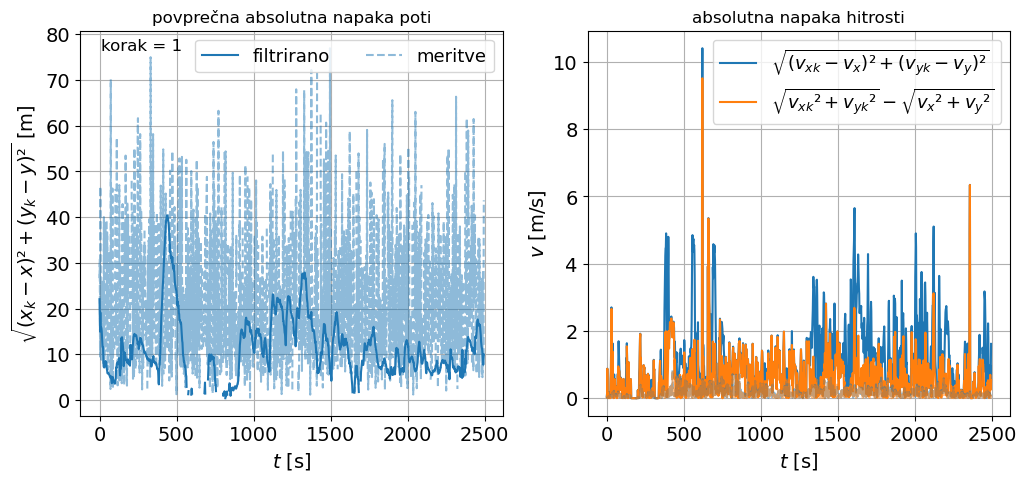

In [10]:
#rez
napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
napaka_v = np.sqrt((kvx-rvx)**2+(kvy-rvy)**2)
napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
#meritve
napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)
napaka_vm = np.sqrt((kvx-pvx)**2+(kvy-pvy)**2)
napaka_v2m = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(pvx**2+pvy**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(t,napaka_sm,'C0--', alpha=0.5)

ax1.plot(t,napaka_s,'C0',label='$s$')
ax2.plot(t,napaka_v,'C0',label='$\sqrt{(v_{xk}-v_x)²+(v_{yk}-v_y)²}$')
ax2.plot(t,napaka_v2,'C1',label='$\sqrt{v_{xk}²+v_{yk}²} - \sqrt{v_{x}²+v_y²}$')

ax2.plot(t,napaka_vm,'C0--', alpha=0.5)
ax2.plot(t,napaka_v2m,'C1--', alpha=0.5)

ax1.grid()
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$\sqrt{(x_k-x)²+(y_k-y)²}$ [m]")
ax1.set_title('povprečna absolutna napaka poti',fontsize=12)
ax1.legend(handles=[plt.Line2D([], [], linestyle='-', label='filtrirano'),
                                        plt.Line2D([], [], linestyle='--', alpha=0.5, label='meritve')],
                               loc='best', ncol=2, fontsize=13)
ax2.legend(ncol=1,fontsize=13)
ax2.grid()
ax2.set_xlabel("$t$ [s]")
ax2.set_ylabel("$v$ [m/s]")
ax2.set_title('absolutna napaka hitrosti',fontsize=12)
plt.text(0.05,0.98,f'korak = {step_pos}',fontsize=12, ha='left', va='top', transform=ax1.transAxes)
#plt.savefig('slike/napaka_poti_hitrosti.pdf')
plt.show()

## vpliv koraka

In [11]:
nx=[]
ny=[]
nvx=[]
nvy=[]
koraki=[]
ns=[]
nv=[]
nv2=[]
for step in range(1,50,2):
    rx,ry,rvx,rvy = Kalman2D(step_pos=step,step_v=step)
    napaka_x = sum(abs(kx-rx))
    napaka_y = sum(abs(ky-ry))
    # napaka_vx = sum(abs(kvx-rvx))
    # napaka_vy = sum(abs(kvy-rvy))
    # napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
    napaka_s = napaka_x + napaka_y
    #napaka_v = np.sqrt((kvx-rvx)**2+(kvy-rvy)**2) #nan vrednost?!
    napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
    # nx.append(napaka_x)
    # ny.append(napaka_y)
    # nvx.append(napaka_vx)
    # nvy.append(napaka_vy)
    ns.append(np.sum(napaka_s))
    #nv.append(np.sum(napaka_v))
    nv2.append(np.sum(napaka_v2))
    koraki.append(step)

In [12]:
koraki_pos=[]
ns_pos=[]
nv_pos=[]
for step in range(1,50,2):
    rx,ry,rvx,rvy = Kalman2D(step_pos=step,step_v=1)
    napaka_x = sum(abs(kx-rx))
    napaka_y = sum(abs(ky-ry))
    napaka_s = napaka_x + napaka_y
    napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
    ns_pos.append(np.sum(napaka_s))
    nv_pos.append(np.sum(napaka_v2))
    koraki_pos.append(step)
print('izračunano')

koraki_v=[]
ns_v=[]
nv_v=[]
for step in range(1,50,2):
    rx,ry,rvx,rvy = Kalman2D(step_pos=1,step_v=step)
    napaka_x = sum(abs(kx-rx))
    napaka_y = sum(abs(ky-ry))
    napaka_s = napaka_x + napaka_y
    napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
    ns_v.append(np.sum(napaka_s))
    nv_v.append(np.sum(napaka_v2))
    koraki_v.append(step)

KeyboardInterrupt: 

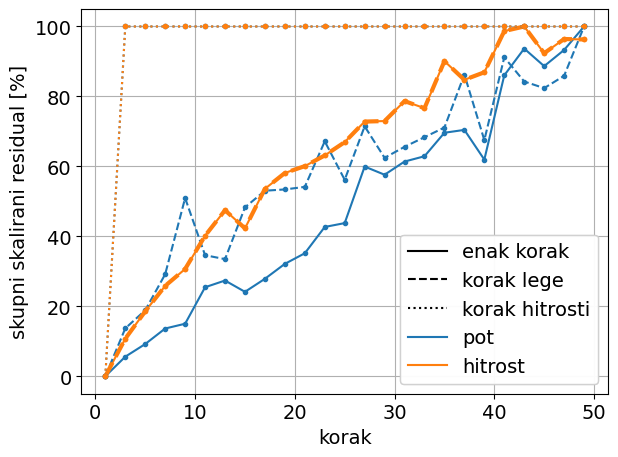

In [ ]:
pot_normalized = ns / np.sum(np.abs(kx + ky))
pot_normalized_scaled = (pot_normalized-np.min(pot_normalized)) / (np.max(pot_normalized)-np.min(pot_normalized))*100
hitrost_normalized = nv2 / np.sum(np.sqrt(kvx**2 + kvy**2))
hitrost_normalized_scaled = (hitrost_normalized-np.min(hitrost_normalized))/(np.max(hitrost_normalized)-np.min(hitrost_normalized))*100

pot_pos = ns_pos / np.sum(np.abs(kx + ky))
pot_pos_scaled = (pot_pos-np.min(pot_pos)) / (np.max(pot_pos)-np.min(pot_pos))*100
hitrost_pos = nv2 / np.sum(np.sqrt(kvx**2 + kvy**2))
hitrost_pos_scaled = (hitrost_pos-np.min(hitrost_pos))/(np.max(hitrost_pos)-np.min(hitrost_pos))*100

pot_normalized = ns_v / np.sum(np.abs(kx + ky))
pot_v_scaled = (pot_normalized-np.min(pot_normalized)) / (np.max(pot_normalized)-np.min(pot_normalized))*100
hitrost_normalized = nv_v / np.sum(np.sqrt(kvx**2 + kvy**2))
hitrost_v_scaled = (hitrost_normalized-np.min(hitrost_normalized))/(np.max(hitrost_normalized)-np.min(hitrost_normalized))*100

plt.plot(koraki, pot_normalized_scaled,'C0.-', label='pot')
plt.plot(koraki, hitrost_normalized_scaled,'C1.-', label='hitrost')

plt.plot(koraki_pos, pot_pos_scaled,'C0.--')
plt.plot(koraki_pos, hitrost_pos_scaled,'C1.--',linewidth=3)

plt.plot(koraki_v, pot_v_scaled,'C0.:')
plt.plot(koraki_v, hitrost_v_scaled,'C1.:')

legenda=plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label=f'enak korak'),
                            plt.Line2D([], [], color='k', linestyle='--', label='korak lege'),
                            plt.Line2D([], [], color='k', linestyle=':', label='korak hitrosti'),
                            plt.Line2D([], [], color='C0', label='pot'),
                            plt.Line2D([], [], color='C1', label='hitrost')],
                    loc='best', ncol=1, fontsize=14)
plt.gca().add_artist(legenda)
plt.grid()
plt.xlabel('korak')
plt.ylabel('skupni skalirani residual [%]')
plt.tight_layout()
#plt.savefig('slike/vpliv_koraka.pdf')
plt.show()

## 2d plot

In [ ]:
koraki=[]
ns=[]
nv=[]
for step_pos in range(1,30,2):
    for step_v  in range(1,30,2):
        rx,ry,rvx,rvy = Kalman2D(step_pos=step_pos,step_v=step_v)
        napaka_x = sum(abs(kx-rx))
        napaka_y = sum(abs(ky-ry))
        napaka_s = napaka_x + napaka_y
        napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
        ns.append(np.sum(napaka_s))
        nv.append(np.sum(napaka_v2))
        koraki.append((step_pos,step_v))

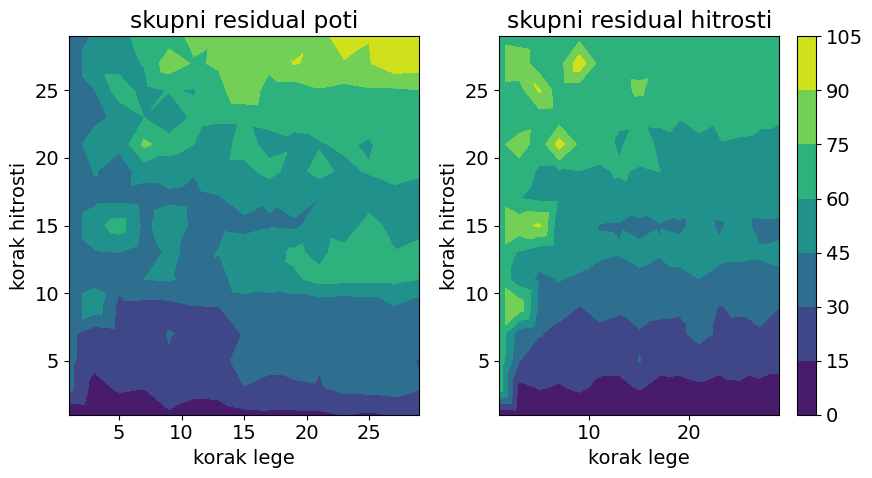

In [ ]:
koraki=np.array(koraki)
ns = np.array(ns)
ns_normalized = (ns - np.min(ns)) / (np.max(ns) - np.min(ns)) * 100
nv = np.array(nv)
nv_normalized = (nv - np.min(nv)) / (np.max(nv) - np.min(nv)) * 100

tri = Triangulation(koraki[:, 0], koraki[:, 1])
fig, (ax1,ax2) = plt.subplots(nrows=1,ncols=2,figsize=(9, 5))
contour = ax1.tricontourf(tri, ns_normalized, cmap='viridis')
contour = ax2.tricontourf(tri, nv_normalized, cmap='viridis')
fig.colorbar(contour, ax=ax2)
#plt.scatter(koraki[:,0],koraki[:,1],c=nv, cmap='viridis')
ax1.set_xlabel('korak lege')
ax1.set_ylabel('korak hitrosti')
ax1.set_title('skupni residual poti')
ax2.set_xlabel('korak lege')
ax2.set_ylabel('korak hitrosti')
ax2.set_title('skupni residual hitrosti')
plt.tight_layout()
#plt.savefig('slike/vpliv_korakov_2dplot.pdf')

# ni podatkov hitrosti

/tmp/ipykernel_13776/2542818962.py:5: RuntimeWarning: invalid value encountered in sqrt
  napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
/tmp/ipykernel_13776/2542818962.py:9: RuntimeWarning: invalid value encountered in sqrt
  napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)


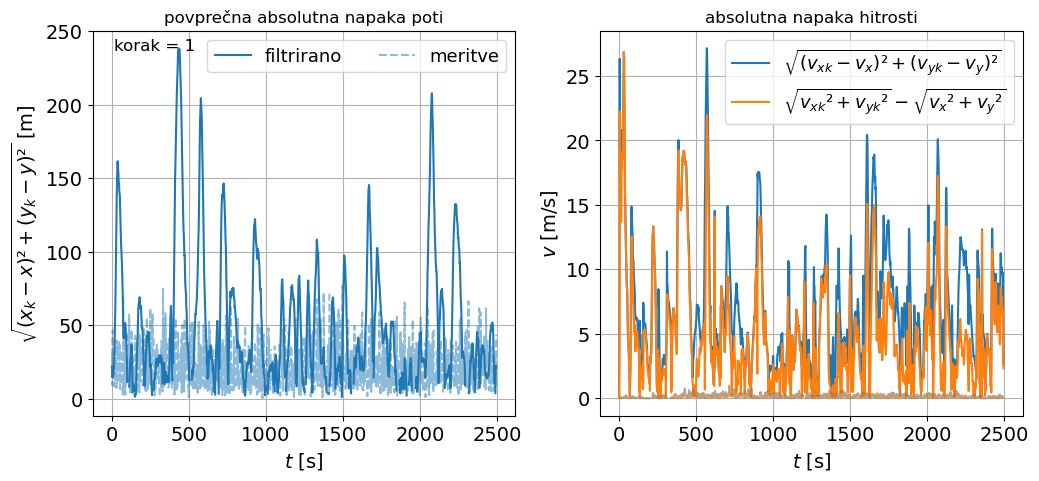

In [13]:
step = 1
rx,ry,rvx,rvy = Kalman2D(step_pos=step,step_v=10000)

#rez
napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
napaka_v = np.sqrt((kvx-rvx)**2+(kvy-rvy)**2)
napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
#meritve
napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)
napaka_vm = np.sqrt((kvx-pvx)**2+(kvy-pvy)**2)
napaka_v2m = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(pvx**2+pvy**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(t,napaka_sm,'C0--', alpha=0.5)

ax1.plot(t,napaka_s,'C0',label='$s$')
ax2.plot(t,napaka_v,'C0',label='$\sqrt{(v_{xk}-v_x)²+(v_{yk}-v_y)²}$')
ax2.plot(t,napaka_v2,'C1',label='$\sqrt{v_{xk}²+v_{yk}²} - \sqrt{v_{x}²+v_y²}$')

ax2.plot(t,napaka_vm,'C0--', alpha=0.5)
ax2.plot(t,napaka_v2m,'C1--', alpha=0.5)

ax1.grid()
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$\sqrt{(x_k-x)²+(y_k-y)²}$ [m]")
ax1.set_title('povprečna absolutna napaka poti',fontsize=12)
ax1.legend(handles=[plt.Line2D([], [], linestyle='-', label='filtrirano'),
                                        plt.Line2D([], [], linestyle='--', alpha=0.5, label='meritve')],
                               loc='best', ncol=2, fontsize=13)
ax2.legend(ncol=1,fontsize=13)
ax2.grid()
ax2.set_xlabel("$t$ [s]")
ax2.set_ylabel("$v$ [m/s]")
ax2.set_title('absolutna napaka hitrosti',fontsize=12)
plt.text(0.05,0.98,f'korak = {step}',fontsize=12, ha='left', va='top', transform=ax1.transAxes)
#plt.savefig('slike/napaka_poti_brez_vdata.pdf')
plt.show()

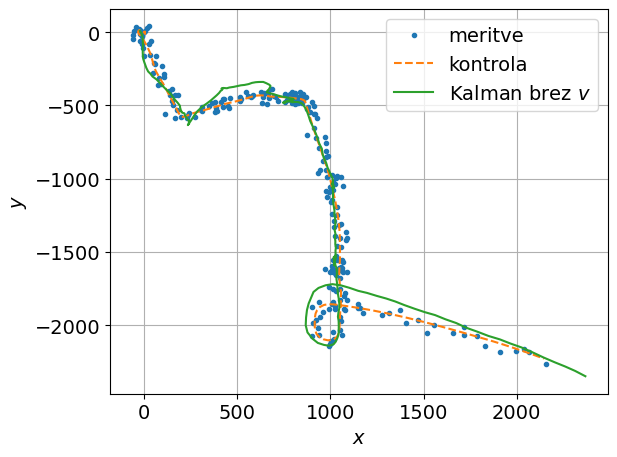

In [14]:
start, stop = (0,250)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman brez $v$')
plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_brez_vdata_detajl.pdf')

## ni podatkov lege

/tmp/ipykernel_20140/1764706151.py:9: RuntimeWarning: invalid value encountered in sqrt
  napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)


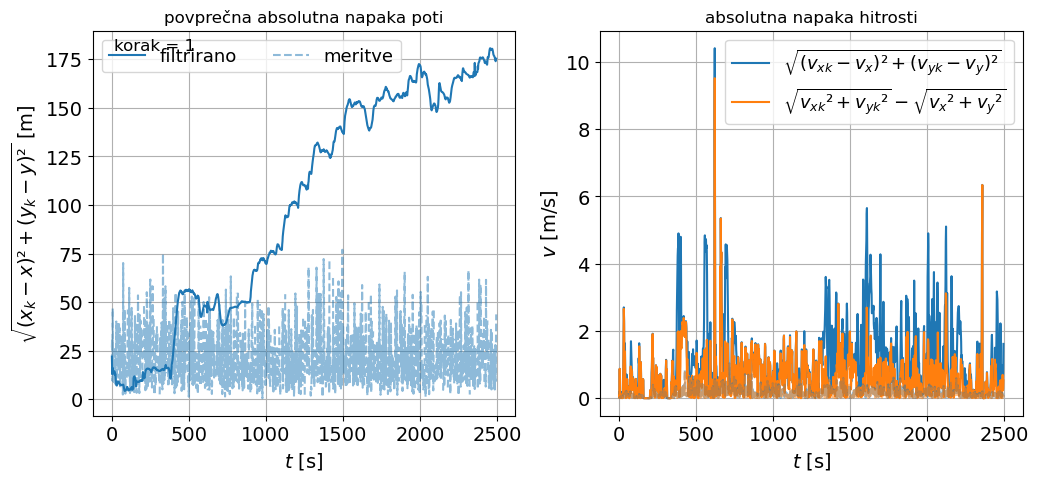

In [42]:
step = 1
rx,ry,rvx,rvy = Kalman2D(step_pos=10000,step_v=step)

#rez
napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
napaka_v = np.sqrt((kvx-rvx)**2+(kvy-rvy)**2)
napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
#meritve
napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)
napaka_vm = np.sqrt((kvx-pvx)**2+(kvy-pvy)**2)
napaka_v2m = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(pvx**2+pvy**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(t,napaka_sm,'C0--', alpha=0.5)

ax1.plot(t,napaka_s,'C0',label='$s$')
ax2.plot(t,napaka_v,'C0',label='$\sqrt{(v_{xk}-v_x)²+(v_{yk}-v_y)²}$')
ax2.plot(t,napaka_v2,'C1',label='$\sqrt{v_{xk}²+v_{yk}²} - \sqrt{v_{x}²+v_y²}$')

ax2.plot(t,napaka_vm,'C0--', alpha=0.5)
ax2.plot(t,napaka_v2m,'C1--', alpha=0.5)

ax1.grid()
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$\sqrt{(x_k-x)²+(y_k-y)²}$ [m]")
ax1.set_title('povprečna absolutna napaka poti',fontsize=12)
ax1.legend(handles=[plt.Line2D([], [], linestyle='-', label='filtrirano'),
                                        plt.Line2D([], [], linestyle='--', alpha=0.5, label='meritve')],
                               loc='best', ncol=2, fontsize=13)
ax2.legend(ncol=1,fontsize=13)
ax2.grid()
ax2.set_xlabel("$t$ [s]")
ax2.set_ylabel("$v$ [m/s]")
ax2.set_title('absolutna napaka hitrosti',fontsize=12)
plt.text(0.05,0.98,f'korak = {step}',fontsize=12, ha='left', va='top', transform=ax1.transAxes)
#plt.savefig('slike/napaka_poti_brez_lege.pdf')
plt.show()

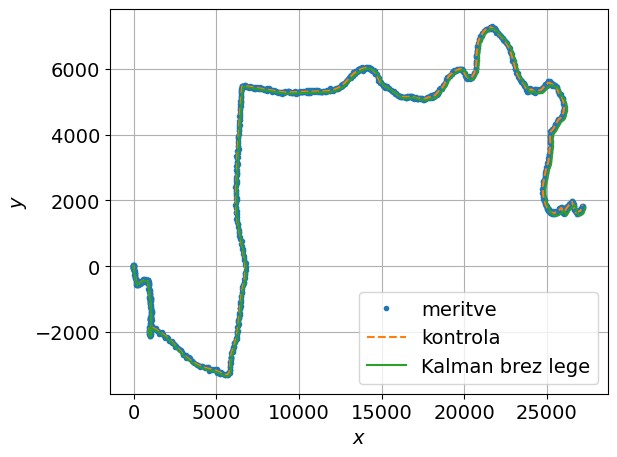

In [43]:
start, stop = (0,2500)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman brez lege')
plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_brez_lege.pdf')

## ni pospeškov

brez kontrolnega vektorja


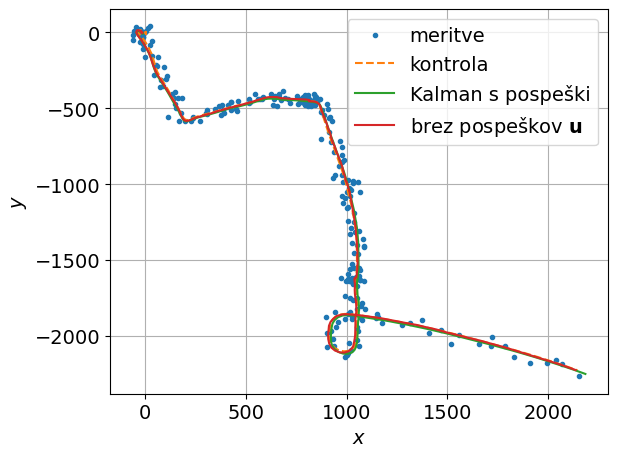

In [61]:
step=1
#rxb,ryb,rvxb,rvyb = Kalman_old(step,step)
rxb,ryb,rvxb,rvyb = Kalman2D(step,step,brez_kontrole=True) #ni pospeška
rx,ry,rvx,rvy = Kalman2D(step,step)

start, stop = (0,250)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman s pospeški')
plt.plot(rxb[start:stop],ryb[start:stop],'-',label='brez pospeškov $\mathbf{u}$')

plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_brez_adata_detajl.pdf')

/tmp/ipykernel_3662/1557518764.py:5: RuntimeWarning: invalid value encountered in sqrt
  napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
/tmp/ipykernel_3662/1557518764.py:9: RuntimeWarning: invalid value encountered in sqrt
  napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)


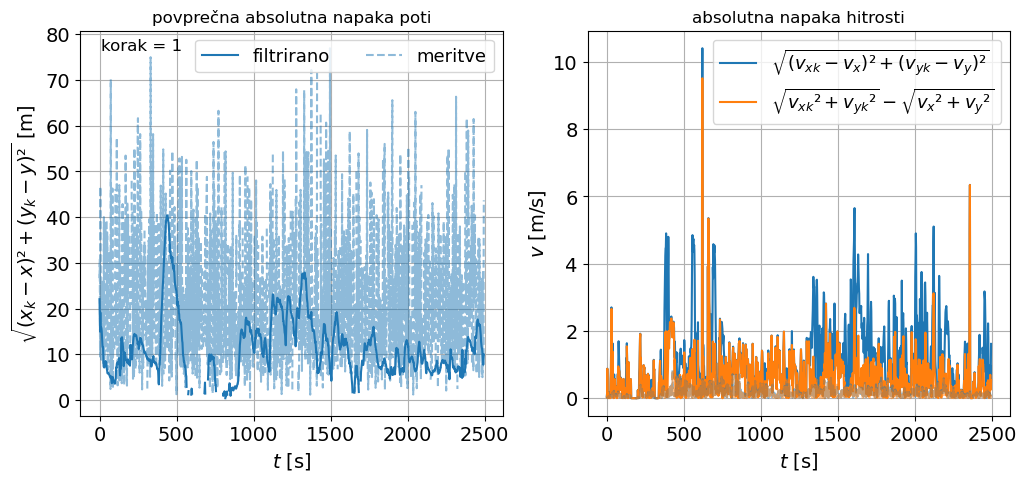

In [62]:
#rx,ry,rvx,rvy = Kalman_old(step_pos=step,step_v=step)
rx,ry,rvx,rvy = Kalman2D(step,step,brez_kontrole=False) #ni pospeška

#rez
napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
napaka_v = np.sqrt((kvx-rvx)**2+(kvy-rvy)**2)
napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
#meritve
napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)
napaka_vm = np.sqrt((kvx-pvx)**2+(kvy-pvy)**2)
napaka_v2m = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(pvx**2+pvy**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(t,napaka_sm,'C0--', alpha=0.5)

ax1.plot(t,napaka_s,'C0',label='$s$')
ax2.plot(t,napaka_v,'C0',label='$\sqrt{(v_{xk}-v_x)²+(v_{yk}-v_y)²}$')
ax2.plot(t,napaka_v2,'C1',label='$\sqrt{v_{xk}²+v_{yk}²} - \sqrt{v_{x}²+v_y²}$')

ax2.plot(t,napaka_vm,'C0--', alpha=0.5)
ax2.plot(t,napaka_v2m,'C1--', alpha=0.5)

ax1.grid()
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$\sqrt{(x_k-x)²+(y_k-y)²}$ [m]")
ax1.set_title('povprečna absolutna napaka poti',fontsize=12)
ax1.legend(handles=[plt.Line2D([], [], linestyle='-', label='filtrirano'),
                                        plt.Line2D([], [], linestyle='--', alpha=0.5, label='meritve')],
                               loc='best', ncol=2, fontsize=13)
ax2.legend(ncol=1,fontsize=13)
ax2.grid()
ax2.set_xlabel("$t$ [s]")
ax2.set_ylabel("$v$ [m/s]")
ax2.set_title('absolutna napaka hitrosti',fontsize=12)
plt.text(0.05,0.98,f'korak = {step}',fontsize=12, ha='left', va='top', transform=ax1.transAxes)
#plt.savefig('slike/napaka_poti_brez_adata.pdf')
plt.show()

## ni lege in pospeškov

brez kontrolnega vektorja
brez kontrolnega vektorja


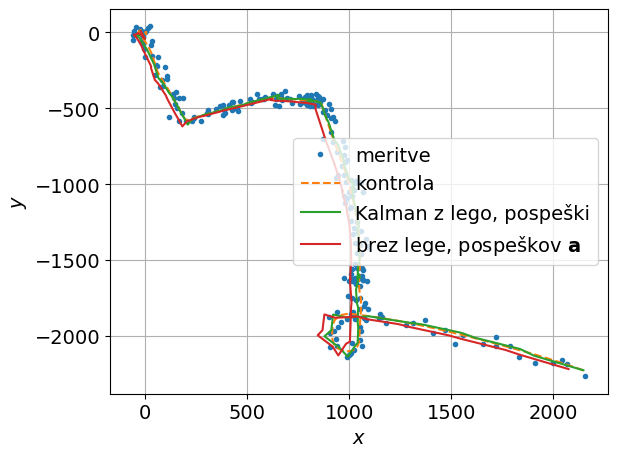

In [63]:
step=5
rxb,ryb,rvxb,rvyb = Kalman2D(step_pos=10000,step_v=step,brez_kontrole=True)
rx,ry,rvx,rvy = Kalman2D(step,step,brez_kontrole=True)

start, stop = (0,250)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman z lego, pospeški')
plt.plot(rxb[start:stop],ryb[start:stop],'-',label='brez lege, pospeškov $\mathbf{a}$')

plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_brez_lege_adata.pdf')

## le pospeški

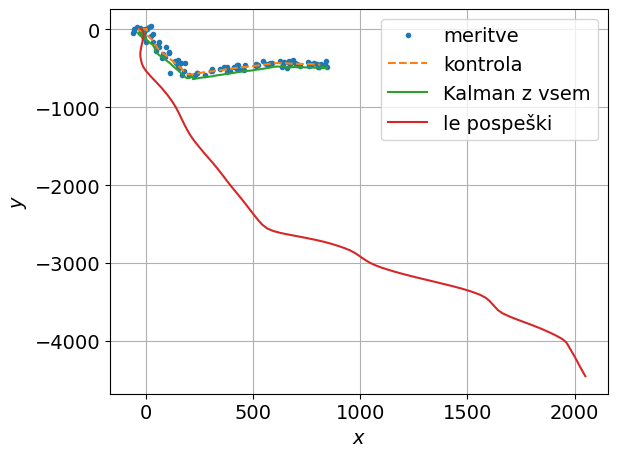

In [41]:
rxb,ryb,rvxb,rvyb = Kalman2D(step_pos=10000,step_v=10000,brez_kontrole=False)
rx,ry,rvx,rvy = Kalman2D(step,step,brez_kontrole=False)

start, stop = (0,100)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman z vsem')
plt.plot(rxb[start:stop],ryb[start:stop],'-',label='le pospeški')

plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_le_pospeški_detajl.pdf')

# residuali

In [64]:
residual =[]
korak=[]
for step in [1,50,100,200]:
    rx,ry,rvx,rvy = Kalman2D(step,step)
    H=np.identity(4)
    residual_=[]
    for i in range(len(rx)):
        x = np.array([rx[i],ry[i],rvx[i],rvy[i]])
        z = np.array([kx[i],ky[i],kvx[i],kvy[i]])
        r_i= np.linalg.norm(z - np.dot(H,x))
        residual_.append(r_i)
    residual.append(residual_)
    korak.append(step)

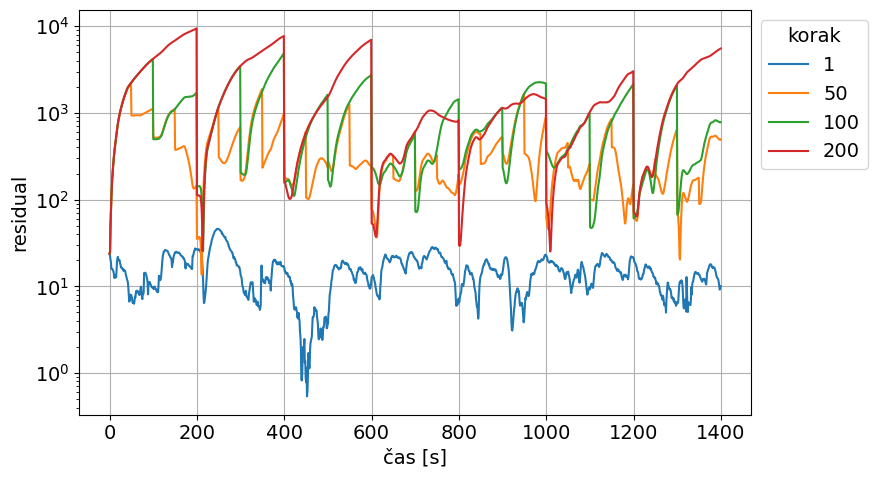

In [65]:
plt.figure(figsize=(9,5))
for i in  range(len(residual)):
    plt.plot(residual[i],label=f'{korak[i]}')
plt.yscale('log')
plt.xlabel('čas [s]')
plt.ylabel('residual')
plt.legend(title='korak',bbox_to_anchor=(1,1))
plt.grid()
plt.tight_layout()
#plt.savefig('slike/residuali.pdf')

# kovarianca

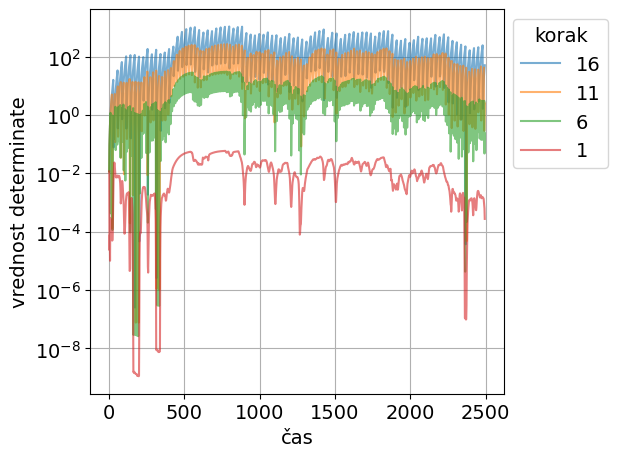

In [66]:
step=100
determinanta=[]
korak=[]
for step in range(1,20,5):
    cov = Kalman2D(step,step,cov=True)
    rx,ry,rvx,rvy = Kalman2D(step,step)
    d = [np.linalg.det(cov_mat) for cov_mat in cov]
    determinanta.append(d)
    korak.append(step)
determinanta=np.array(determinanta)
for i in range(len(determinanta)):
    plt.plot(t,determinanta[-i-1],label=f'{korak[-i-1]}',alpha=0.6)
# residual=[]
# H=np.identity(4)
# for i in range(len(rx)):
#     x = np.array([rx[i],ry[i],rvx[i],rvy[i]])
#     z = np.array([kx[i],ky[i],kvx[i],kvy[i]])
#     r_i= np.linalg.norm(z - np.dot(H,x))
#     residual.append(r_i)
# residual=np.array(residual)
# plt.plot(t,residual/10,label='skaliran residual')
# plt.title(f'korak = {step}')
plt.xlabel('čas')
plt.ylabel('vrednost determinate')
plt.grid()
plt.yscale('log')
plt.legend(title='korak',bbox_to_anchor=(1,1))
plt.tight_layout()
#plt.savefig('slike/det_cov_matrike.pdf')
plt.show()

## napačen začetni približek

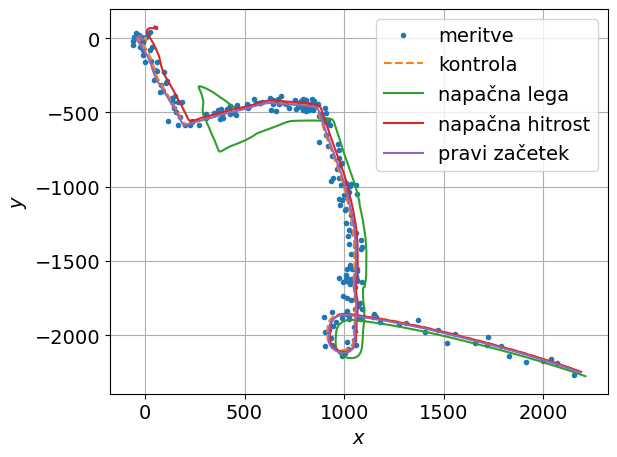

In [28]:
step=1
x_0 = [px[0]+500, py[0]-500, pvx[0], pvy[0]]
rx,ry,rvx,rvy = Kalman2D(step,step,x_0=x_0)
rx_,ry_,rvx_,rvy_ = Kalman2D(step,step)#ref
x_0 = [px[0], py[0], pvx[0]+500, pvy[0]+500]
rxv,ryv,rvxv,rvyv = Kalman2D(step,step,x_0=x_0)

start, stop = (0,250)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='napačna lega')
plt.plot(rxv[start:stop],ryv[start:stop],'-',label='napačna hitrost')
plt.plot(rx_[start:stop],ry_[start:stop],'-',label='pravi začetek')

plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_zamiki.pdf')

In [16]:
zamiki=[]
ns=[]
nv=[]
for zamik_x in range(-500,501,50):
    for zamik_y  in range(-500,501,50):
        x_0 = [px[0]+zamik_x, py[0]+zamik_y, pvx[0], pvy[0]]
        rx,ry,rvx,rvy = Kalman2D(step_pos=1,step_v=1,x_0=x_0)
        napaka_x = sum(abs(kx-rx))
        napaka_y = sum(abs(ky-ry))
        napaka_s = napaka_x + napaka_y
        napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
        ns.append(np.sum(napaka_s))
        nv.append(np.sum(napaka_v2))
        zamiki.append((zamik_x,zamik_y))

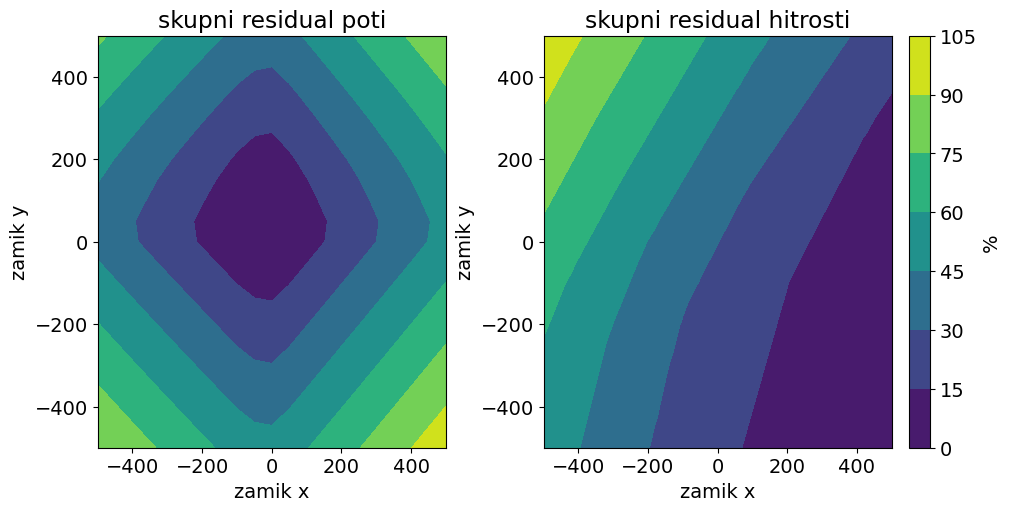

In [19]:
zamiki=np.array(zamiki)
ns = np.array(ns)
ns_normalized = (ns - np.min(ns)) / (np.max(ns) - np.min(ns)) * 100
nv = np.array(nv)
nv_normalized = (nv - np.min(nv)) / (np.max(nv) - np.min(nv)) * 100

tri = Triangulation(zamiki[:, 0], zamiki[:, 1])
fig, (ax1,ax2) = plt.subplots(nrows=1,ncols=2,figsize=(10, 5), layout='constrained')
contour = ax1.tricontourf(tri, ns_normalized, cmap='viridis')
contour = ax2.tricontourf(tri, nv_normalized, cmap='viridis')
fig.colorbar(contour, ax=ax2,label='%')
#plt.scatter(koraki[:,0],koraki[:,1],c=nv, cmap='viridis')
ax1.set_xlabel('zamik x')
ax1.set_ylabel('zamik y')
ax1.set_title('skupni residual poti')
ax2.set_xlabel('zamik x')
ax2.set_ylabel('zamik y')
ax2.set_title('skupni residual hitrosti')
#plt.tight_layout()
#plt.savefig('slike/vpliv_zamikov_lege.pdf')

In [20]:
zamiki=[]
ns=[]
nv=[]
for zamik_x in range(-500,501,100):
    for zamik_y  in range(-500,501,100):
        x_0 = [px[0], py[0], pvx[0]+zamik_x, pvy[0]+zamik_y]
        rx,ry,rvx,rvy = Kalman2D(step_pos=1,step_v=1,x_0=x_0)
        napaka_x = sum(abs(kx-rx))
        napaka_y = sum(abs(ky-ry))
        napaka_s = napaka_x + napaka_y
        napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
        ns.append(np.sum(napaka_s))
        nv.append(np.sum(napaka_v2))
        zamiki.append((zamik_x,zamik_y))

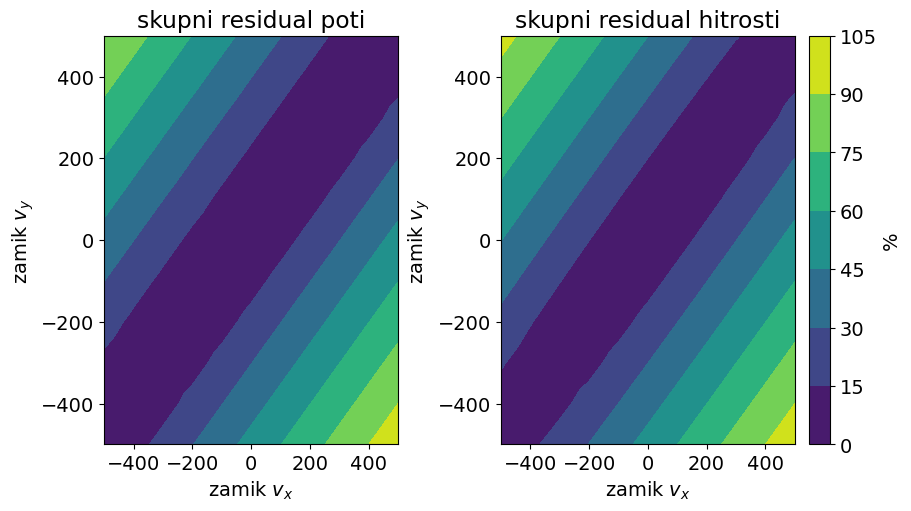

In [25]:
zamiki=np.array(zamiki)
ns = np.array(ns)
ns_normalized = (ns - np.min(ns)) / (np.max(ns) - np.min(ns)) * 100
nv = np.array(nv)
nv_normalized = (nv - np.min(nv)) / (np.max(nv) - np.min(nv)) * 100

tri = Triangulation(zamiki[:, 0], zamiki[:, 1])
fig, (ax1,ax2) = plt.subplots(nrows=1,ncols=2,figsize=(9, 5),layout='constrained')
contour = ax1.tricontourf(tri, ns_normalized, cmap='viridis')
contour = ax2.tricontourf(tri, nv_normalized, cmap='viridis')
fig.colorbar(contour, ax=ax2, label='%')
#plt.scatter(koraki[:,0],koraki[:,1],c=nv, cmap='viridis')
ax1.set_xlabel('zamik $v_x$')
ax1.set_ylabel('zamik $v_y$')
ax1.set_title('skupni residual poti')
ax2.set_xlabel('zamik $v_x$')
ax2.set_ylabel('zamik $v_y$')
ax2.set_title('skupni residual hitrosti')
#plt.tight_layout()
#plt.savefig('slike/vpliv_zamikov_hitrosti.pdf')

# 3D primer

In [9]:
def hour_to_sec(i):
    h, m, s = i.split(':')
    return float(h) * 3600 + float(m) * 60 + float(s)
def GPS(i):
    x, y = map(float, i.split())
    return x, y
data = pd.read_csv('podatki/DBF22-test-1.csv', skiprows=0, converters={
    0: lambda i: 0,  # Column 0 not useful
    1: hour_to_sec,  # Column 1
    5: GPS  # Column 5
})
t=data['Time'].values #s
t=t-t[0]
ground_speed=data['GSpd(kts)'].values* 	0.514444 #knots -> m/s
loc=data['GPS'].values #deg?
px=[loc[i][0] for i in range(len(loc))]
py=[loc[i][1] for i in range(len(loc))]
altitude=data['GAlt(m)'].values #m

i=236
t1=[t[i]]
gr_spd=[ground_speed[i]]
x=[px[i]]
y=[py[i]]
alt=[altitude[i]]
i=237
while ground_speed[i] > 0:
    t1.append(t[i])
    x.append(px[i])
    y.append(py[i])
    alt.append(altitude[i])
    gr_spd.append(ground_speed[i])
    i+=1
t1=np.array(t1-t1[0])

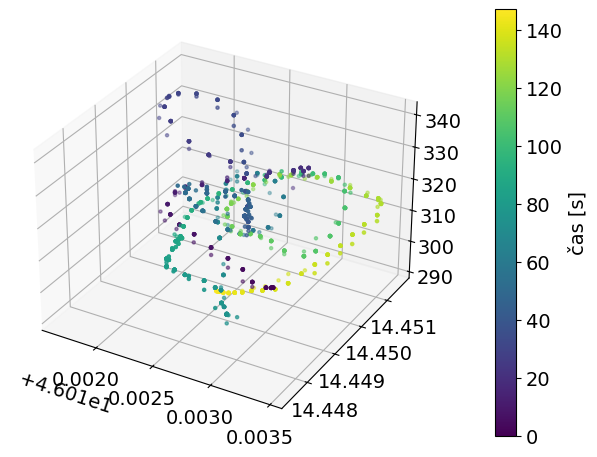

In [10]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
sc=ax.scatter(x, y, alt, c=t1, cmap='viridis', marker='.')
#norm = plt.Normalize(t1.min(), t1.max())
cbar = fig.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label('čas [s]')
plt.grid(b=None)
plt.axis('on')
plt.tight_layout()
#plt.savefig('slike/primer_3d.pdf')
plt.show()

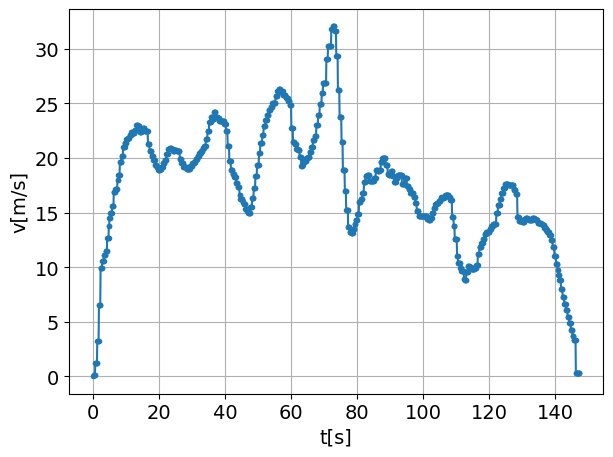

In [12]:
plt.plot(t1,gr_spd,'.-')
plt.grid()
plt.xlabel('t[s]')
plt.ylabel('v[m/s]')
plt.tight_layout()
#plt.savefig('slike/3d_hitrosti_krog.pdf')

In [75]:
def Kalman3D(cov=False):
    # PODATKI
    dt=1.783 #s
    sigma_xyz = 25 #m abs. napaka
    sigma_a = 0.05 #m/s**2
    sigma_v=0.01*np.abs(ground_speed) #ni konst. relat.napaka
    sigma_v=np.array([1/3.6 if i>1/3.6 else i for i in sigma_v]) #omejimo na 1 km/h=1/3,6=0,2777 m/s

    f=KalmanFilter(dim_x=6,dim_z=6,dim_u=0) #u=kontrola, x-kaj spremljamo, z-kaj je izmerjeno
    f.x=np.transpose([[px[0],py[0],altitude[0],0,0,0]]) #initial
    sigma_xx=sigma_yy=sigma_xy=sigma_xz=sigma_yz=sigma_zz = sigma_xyz
    sigma_vxvx=sigma_vyvy=sigma_vzvz = sigma_v[0]
    sigma_vxvy=sigma_vxvz=sigma_vyvz = sigma_v[0]
    sigma_xvx=sigma_xvy=sigma_xvz=sigma_yvx=sigma_yvy=sigma_yvz=sigma_zvx=sigma_zvy=sigma_zvz = 0 #ok???
    f.P = np.array([[sigma_xx, sigma_xy, sigma_xvx, sigma_xz, sigma_xvy, sigma_xvz],
                    [sigma_xy, sigma_yy, sigma_yvx, sigma_yz, sigma_yvy, sigma_xvz],
                    [sigma_xz, sigma_yz, sigma_zvx, sigma_zz, sigma_zvy, sigma_zvz],
                    [sigma_xvx, sigma_yvx, sigma_vxvx, sigma_zvx, sigma_vxvy, sigma_vxvz],
                    [sigma_xvy, sigma_yvy, sigma_vxvy, sigma_zvy, sigma_vyvy, sigma_vyvz],
                    [sigma_xvz, sigma_yvz, sigma_vxvz, sigma_vxvz, sigma_vyvz, sigma_vzvz]]) #covariance matrix

    Q_a=np.diag([sigma_a**2,sigma_a**2,sigma_a**2,sigma_a**2,sigma_a**2,sigma_a**2],)#napaka pospeškov
    f.Q=Q_a #process noise
    #f.Q = filterpy.common.Q_discrete_white_noise(dim=4, dt=0.1, var=0.13)
    R_v=np.diag([sigma_xyz**2,sigma_xyz**2,sigma_xyz**2,sigma_v[0]**2,sigma_v[0]**2,sigma_v[0]**2])#napaka hitrosti in pomikov, šum
    f.R = R_v # measurment noise

    f.H = np.array([[1,0,0,0,0,0], #merimo le lego!
                    [0,1,0,0,0,0],
                    [0,0,1,0,0,0],
                    [0,0,0,0,0,0],
                    [0,0,0,0,0,0],
                    [0,0,0,0,0,0]]) #measurment matrix - kaj merimo, kaj računamo! izmerek z=H*x OK
    f.F=np.block([[np.identity(3), np.identity(3)*dt],
                [np.zeros((3,3)), np.identity(3)]]) #state transition matrix OK
    f.B = np.block([[np.identity(3)*0.5*dt**2],
                    [np.identity(3)]]) #control matrix OK

    saver = filterpy.common.Saver(f)
    for i in range(len(px)):
        f.predict()
        z=np.transpose([[px[i],py[i],altitude[i],0,0,0]])
        R_i=np.diag([sigma_xyz**2,sigma_xyz**2,sigma_xyz**2,sigma_v[i]**2,sigma_v[i]**2,sigma_v[i]**2])
        f.update(z,R=R_i)
        saver.save()
    saver.to_array()
    if cov:
        kovariance = saver.P #to so matrike
        return kovariance
    else:
        res_x= np.transpose(saver.x[:,0])[0]
        res_y= np.transpose(saver.x[:,1])[0]
        res_alt= np.transpose(saver.x[:,2])[0]
        #res_vy= np.transpose(saver.x[:,3])[0]
        return res_x, res_y, res_alt

In [76]:
#Kalman3D()
# singular matrix S !!!

# naravni KS

In [44]:
step=1
t,px,py,pvx,pvy,pax,pay = np.loadtxt('podatki/kalman_cartesian_data.dat',unpack=True)
rx_kks,ry_kks,rvx_kks,rvy_kks = Kalman2D(step,step_v=100000)

In [45]:
t,px,py,pat,par = np.loadtxt('podatki/kalman_relative_data.dat',unpack=True)
kt,kx,ky,kvx,kvy = np.loadtxt('podatki/kalman_cartesian_kontrola.dat',unpack=True)

In [46]:
def Kalman2D_naravni(step,cov=False):
    # PODATKI
    dt=1.783 #s
    sigma_xy = 25 #m abs. napaka
    sigma_a = 0.05 #m/s**2
    #sigma_v=0.01*np.abs(np.sqrt(pvx**2+pvy**2)) #ni konst. relat.napaka hitr ne merimo
    #sigma_v=np.array([1/3.6 if i>1/3.6 else i for i in sigma_v]) #omejimo na 1 km/h=1/3,6=0,2777 m/s

    f=KalmanFilter(dim_x=4,dim_z=4,dim_u=4) #u=kontrola, x-kaj spremljamo, z-kaj je izmerjeno
    # f.B = np.block([[0.5*np.identity(2)*dt**2],
    #                 [np.identity(2)*dt]]) #control transition matrix
    f.x=np.transpose([[px[0],py[0],0,0]]) #initial
    sigma_xx=sigma_yy=sigma_xy
    sigma_vxvx=sigma_vyvy=sigma_vxvy= 0 #sigma_v[0]
    sigma_xvx=sigma_xvy=sigma_yvx=sigma_yvy=0 #ok???
    f.P = np.array([[sigma_xx, sigma_xy, sigma_xvx, sigma_xvy],
                    [sigma_xy, sigma_yy, sigma_yvx, sigma_yvy],
                    [sigma_xvx, sigma_yvx, sigma_vxvx, sigma_vxvy],
                    [sigma_xvy, sigma_yvy, sigma_vxvy, sigma_vyvy]]) #covariance matrix

    Q_a=np.diag([0,0,sigma_a**2*dt**2,sigma_a**2*dt**2],)#napaka pospeškov
    f.Q=Q_a #process noise
    #R_v=np.diag([sigma_xy**2,sigma_xy**2,0,0])#napaka hitrosti in pomikov, šum
    R_v=np.identity(4)*sigma_xy**2 #težave ničel hitrosti
    f.R = R_v # measurment noise

    f.H = np.block([[np.identity(2), np.zeros((2,2))],
                    [np.zeros((2,2)), np.zeros((2,2))]]) #measurment matrix - kaj merimo, kaj računamo! izmerek z=H*x+R
    f.F=np.block([[np.identity(2), np.identity(2)*dt],
                [np.zeros((2,2)), np.identity(2)]]) #state transition matrix

    vx=vy=1 #initial
    saver = filterpy.common.Saver(f)
    for i in range(len(px)):        
        B_i_vv = 1/np.sqrt(vx**2+vy**2) * np.array([[vx,-vy],
                                                    [vy, vx]])
        B_i= np.block([[np.identity(2), np.zeros((2,2))],
                        [np.zeros((2,2)), B_i_vv]])
        u_i=np.transpose([[0,0,pat[i]*dt,par[i]*dt]]) #naravni ks
        c_i = np.dot(B_i,u_i) #kks
        f.predict(u=c_i,B=B_i)
        if i%step==0:
            z=np.transpose([[px[i],py[i],0,0]]) #meritve neznana hitrost!
            #R_i=np.diag([sigma_xy**2,sigma_xy**2,sigma_v[i]**2,sigma_v[i]**2])
            f.update(z)
        saver.save()
        vx = f.x[2][0]
        vy = f.x[3][0]
    saver.to_array()
    if cov:
        kovariance = saver.P #to so matrike
        return kovariance
    else:
        res_x= np.transpose(saver.x[:,0])[0]
        res_y= np.transpose(saver.x[:,1])[0]
        res_vx= np.transpose(saver.x[:,2])[0]
        res_vy= np.transpose(saver.x[:,3])[0]
        return res_x, res_y, res_vx, res_vy

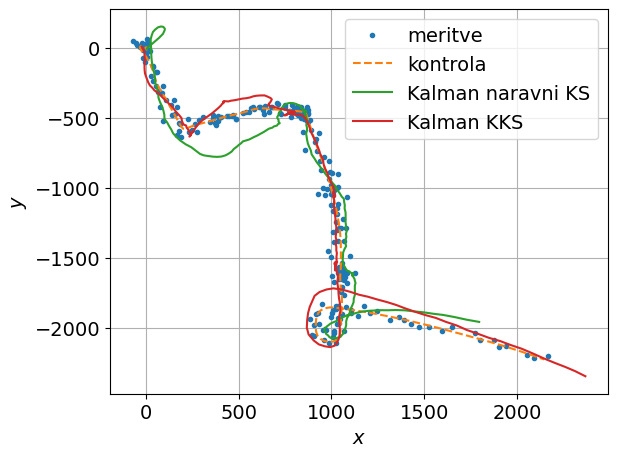

In [47]:
step=1
rx,ry,rvx,rvy=Kalman2D_naravni(step)

start, stop = (0,250)
plt.plot(px[start:stop],py[start:stop],'.',label='meritve')
#plt.plot(px[start:stop:step_pos],py[start:stop:step_pos],'.',label=f'korak = {step_pos}')
plt.plot(kx[start:stop],ky[start:stop],'--',label='kontrola')
plt.plot(rx[start:stop],ry[start:stop],'-',label='Kalman naravni KS')
plt.plot(rx_kks[start:stop],ry_kks[start:stop],'-',label='Kalman KKS')
plt.legend()
plt.grid()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.tight_layout()
#plt.savefig('slike/pot_relat.pdf')

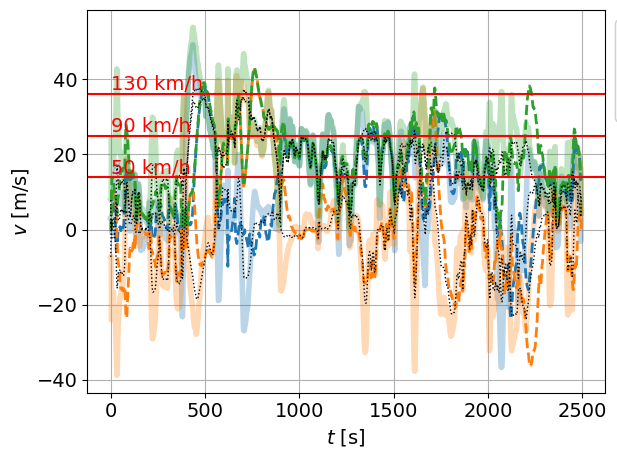

In [48]:
plt.plot(t,rvx_kks,'C0-',label='$v_x$',alpha=0.3,linewidth=4)
plt.plot(t,rvy_kks,'C1-',label='$v_y$',alpha=0.3,linewidth=4)
plt.plot(t,rvx,'C0--',linewidth=2)
plt.plot(t,rvy,'C1--',linewidth=2)
plt.plot(t,np.sqrt(rvx_kks**2+rvy_kks**2),'C2-',label='$\\vec{v}$',alpha=0.3,linewidth=4)
plt.plot(t,np.sqrt(rvx**2+rvy**2),'C2--',linewidth=2)
plt.plot(t,np.sqrt(kvx**2+kvy**2),'k:',linewidth=1)
plt.plot(t,kvx,'k:',linewidth=1)
plt.plot(t,kvy,'k:',linewidth=1)
plt.axhline(130/3.6, color='r')
plt.axhline(90/3.6, color='r')
plt.axhline(50/3.6, color='r')
plt.text(0, 130/3.6+1, '130 km/h', color='r')
plt.text(0, 90/3.6+1, '90 km/h', color='r')
plt.text(0, 50/3.6+1, '50 km/h', color='r')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-',alpha=0.3,linewidth=4, label='Kalman KKS'),
                                         plt.Line2D([], [], color='k', linestyle='--',linewidth=2, label='naravni KS'),
                                        plt.Line2D([], [], color='k', linestyle=':', label='kontrola')],
                                loc='upper left', bbox_to_anchor=(-0,1.15), ncol=3)
a1=plt.gca().add_artist(legend_line_styles)
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='C0', label='$v_x$'),
                                         plt.Line2D([], [], color='C1', label='$v_y$'),
                                         plt.Line2D([], [], color='C2', label='$|\\mathbf{v}|$')],
                                loc='best', bbox_to_anchor=(1,1), ncol=1)
a2=plt.gca().add_artist(legend_line_styles)
plt.grid()
plt.xlabel("$t$ [s]")
plt.ylabel("$v$ [m/s]")
plt.tight_layout()
#plt.savefig('slike/potek_hitrosti_relat.pdf',bbox_inches='tight',bbox_extra_artists=(a1,a2))

/tmp/ipykernel_20140/1883907712.py:2: RuntimeWarning: invalid value encountered in sqrt
  napaka_s_kks = np.sqrt((kx-rx_kks)**2+(ky-ry_kks)*2)
/tmp/ipykernel_20140/1883907712.py:5: RuntimeWarning: invalid value encountered in sqrt
  napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)


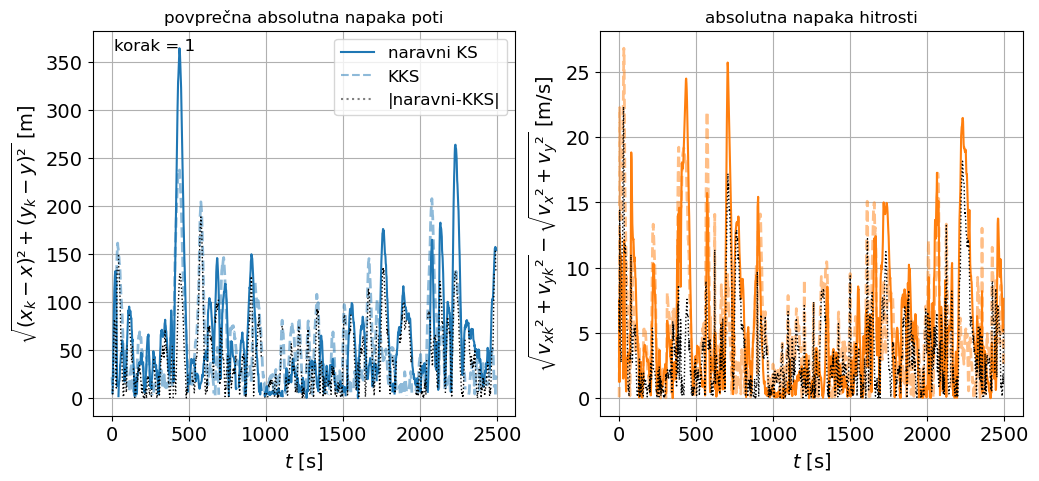

In [49]:
#rez
napaka_s_kks = np.sqrt((kx-rx_kks)**2+(ky-ry_kks)*2)
#napaka_v_kks = np.sqrt((kvx-rvx_kks)**2+(kvy-rvy_kks)**2)
napaka_v2_kks = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx_kks**2+rvy_kks**2))
napaka_s = np.sqrt((kx-rx)**2+(ky-ry)*2)
#napaka_v = np.sqrt((kvx-rvx_kks)**2+(kvy-rvy_kks)**2)
napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
#meritve
#napaka_sm = np.sqrt((kx-px)**2+(ky-py)*2)
#napaka_vm = np.sqrt((kvx-pvx)**2+(kvy-pvy)**2)
#napaka_v2m = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(pvx**2+pvy**2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
ax1.plot(t,napaka_s_kks,'C0--', alpha=0.5,linewidth=2)

ax1.plot(t,napaka_s,'C0',label='$s$')
#ax2.plot(t,napaka_v,'C0',label='$\sqrt{(v_{xk}-v_x)²+(v_{yk}-v_y)²}$')
ax2.plot(t,napaka_v2,'C1',label='$\sqrt{v_{xk}²+v_{yk}²} - \sqrt{v_{x}²+v_y²}$')

#ax2.plot(t,napaka_v_kks,'C0--', alpha=0.5)
ax2.plot(t,napaka_v2_kks,'C1--', alpha=0.5,linewidth=2)

ax1.plot(t,np.abs(napaka_s-napaka_s_kks),'k:',linewidth=1)
ax2.plot(t,np.abs(napaka_v2-napaka_v2_kks),'k:',linewidth=1)

ax1.grid()
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$\sqrt{(x_k-x)²+(y_k-y)²}$ [m]")
ax1.set_title('povprečna absolutna napaka poti',fontsize=12)
ax1.legend(handles=[plt.Line2D([], [], linestyle='-', label='naravni KS'),
                    plt.Line2D([], [], linestyle='--', alpha=0.5, label='KKS'),
                    plt.Line2D([], [], color='k', linestyle=':', alpha=0.5, label='|naravni-KKS|')],
                               loc='best', ncol=1, fontsize=12)
#ax2.legend(ncol=1,fontsize=13)
ax2.grid()
ax2.set_xlabel("$t$ [s]")
ax2.set_ylabel("$\sqrt{v_{xk}²+v_{yk}²} - \sqrt{v_{x}²+v_y²}$ [m/s]")
ax2.set_title('absolutna napaka hitrosti',fontsize=12)
plt.text(0.05,0.98,f'korak = {step}',fontsize=12, ha='left', va='top', transform=ax1.transAxes)
#plt.savefig('slike/napaka_poti_hitrosti_relat.pdf')
plt.show()

In [50]:
koraki=[]
ns=[]
nv=[]
#opomba: naravni ks ima le en korak - pozicija, hitrost se ne beleži!
for step in range(1,30,2):
    rx,ry,rvx,rvy = Kalman2D_naravni(step=step)
    napaka_x = sum(abs(kx-rx))
    napaka_y = sum(abs(ky-ry))
    napaka_s = napaka_x + napaka_y
    napaka_v2 = np.abs(np.sqrt(kvx**2+kvy**2) - np.sqrt(rvx**2+rvy**2))
    ns.append(np.sum(napaka_s))
    nv.append(np.sum(napaka_v2))
    koraki.append((step))
koraki_naravni=np.array(koraki)

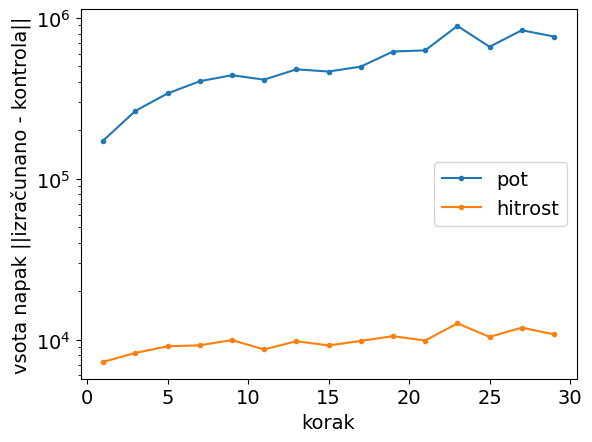

In [52]:
plt.plot(koraki_naravni, ns, '.-', label='pot')
plt.plot(koraki_naravni, nv, '.-', label='hitrost')
plt.xlabel('korak')
plt.ylabel('vsota napak ||izračunano - kontrola||')
plt.legend()
plt.yscale('log')
#plt.savefig('slike/napaka_koraki.pdf')